In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import pandas as pd

Loading data

In [ ]:
import joblib
X_train = joblib.load('/content/X_train_prob.pkl')

y_train = joblib.load('/content/y_train_enc.pkl')

X_test = joblib.load('/content/X_test_prob.pkl')

y_test = joblib.load('/content/y_test_enc.pkl')


In [ ]:
from sklearn.model_selection import train_test_split
X_test, X_val, y_test, y_val = train_test_split(
    X_test,
    y_test,
    test_size=0.50,
    stratify=y_test,
    random_state=42
)

In [ ]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader_mlp = DataLoader(train_dataset, batch_size=32, shuffle=True)

In [ ]:
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader_mlp = DataLoader(val_dataset, batch_size=32, shuffle=True)

In [ ]:
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader_mlp = DataLoader(test_dataset, batch_size=32, shuffle=True)

In [ ]:
num_classes =15

Default MLP

In [ ]:
#implemented using NECO lab04
class MLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )
    def forward(self, x):
        return self.net(x)

mlp_model = MLP(input_dim=1500, num_classes=num_classes)
mlp_optim = torch.optim.Adam(mlp_model.parameters())
criterion = nn.CrossEntropyLoss()

In [ ]:
mlp_train_losses = []
mlp_val_losses  = []

for epoch in range(20):
    mlp_model.train()
    epoch_loss = 0
    for X_batch, y_batch in train_loader_mlp:
        mlp_optim.zero_grad()
        loss = criterion(mlp_model(X_batch), y_batch)
        loss.backward()
        mlp_optim.step()
        epoch_loss += loss.item()
    mlp_train_losses.append(epoch_loss / len(train_loader_mlp))

    mlp_model.eval()
    val_loss = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader_mlp:
            val_loss += criterion(mlp_model(X_batch), y_batch).item()
    mlp_val_losses.append(val_loss / len(test_loader_mlp))

    print(f"Epoch {epoch+1:02d} | Train Loss: {mlp_train_losses[-1]:.4f} | Val Loss: {mlp_val_losses[-1]:.4f}")

Epoch 01 | Train Loss: 1.7016 | Val Loss: 1.2504
Epoch 02 | Train Loss: 1.1040 | Val Loss: 0.9990
Epoch 03 | Train Loss: 0.9058 | Val Loss: 0.8796
Epoch 04 | Train Loss: 0.7952 | Val Loss: 0.7901
Epoch 05 | Train Loss: 0.7055 | Val Loss: 0.7167
Epoch 06 | Train Loss: 0.6295 | Val Loss: 0.6592
Epoch 07 | Train Loss: 0.5718 | Val Loss: 0.6341
Epoch 08 | Train Loss: 0.5296 | Val Loss: 0.5762
Epoch 09 | Train Loss: 0.4935 | Val Loss: 0.5601
Epoch 10 | Train Loss: 0.4670 | Val Loss: 0.5318
Epoch 11 | Train Loss: 0.4441 | Val Loss: 0.5197
Epoch 12 | Train Loss: 0.4254 | Val Loss: 0.5164
Epoch 13 | Train Loss: 0.4057 | Val Loss: 0.5108
Epoch 14 | Train Loss: 0.3879 | Val Loss: 0.4920
Epoch 15 | Train Loss: 0.3705 | Val Loss: 0.4842
Epoch 16 | Train Loss: 0.3562 | Val Loss: 0.4788
Epoch 17 | Train Loss: 0.3429 | Val Loss: 0.4662
Epoch 18 | Train Loss: 0.3303 | Val Loss: 0.4728
Epoch 19 | Train Loss: 0.3198 | Val Loss: 0.4548
Epoch 20 | Train Loss: 0.3072 | Val Loss: 0.4498


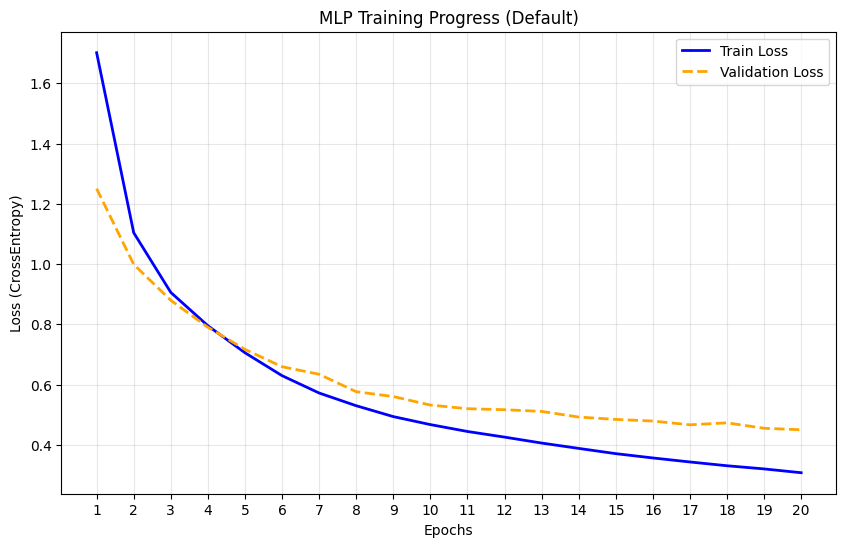

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(mlp_train_losses, label='Train Loss', color='blue', linewidth=2)
plt.plot(mlp_val_losses, label='Validation Loss', color='orange', linestyle='--', linewidth=2)

l=[i for i in range(1,21)]
m=[i for i in range(0,20)]
plt.xticks(m,l)
plt.title('MLP Training Progress (Default)')
plt.xlabel('Epochs')
plt.ylabel('Loss (CrossEntropy)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Tuning

1. Addding Dropout layers

In [ ]:
class MLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.3),              # added
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),              # added
            nn.Linear(64, num_classes)
        )
    def forward(self, x):
        return self.net(x)

mlp_model = MLP(input_dim=1500, num_classes=num_classes)
mlp_optim = torch.optim.Adam(mlp_model.parameters())
criterion = nn.CrossEntropyLoss()

mlp_train_losses = []
mlp_val_losses   = []

for epoch in range(20):
    mlp_model.train()
    epoch_loss = 0
    for X_batch, y_batch in train_loader_mlp:
        mlp_optim.zero_grad()
        loss = criterion(mlp_model(X_batch), y_batch)
        loss.backward()
        mlp_optim.step()
        epoch_loss += loss.item()
    mlp_train_losses.append(epoch_loss / len(train_loader_mlp))

    mlp_model.eval()
    val_loss = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader_mlp:
            val_loss += criterion(mlp_model(X_batch), y_batch).item()
    mlp_val_losses.append(val_loss / len(val_loader_mlp))

    print(f"Epoch {epoch+1:02d} | Train Loss: {mlp_train_losses[-1]:.4f} | Val Loss: {mlp_val_losses[-1]:.4f}")

Epoch 01 | Train Loss: 1.7448 | Val Loss: 1.3006
Epoch 02 | Train Loss: 1.1755 | Val Loss: 1.0655
Epoch 03 | Train Loss: 0.9948 | Val Loss: 0.9417
Epoch 04 | Train Loss: 0.8942 | Val Loss: 0.8617
Epoch 05 | Train Loss: 0.8216 | Val Loss: 0.8134
Epoch 06 | Train Loss: 0.7677 | Val Loss: 0.7644
Epoch 07 | Train Loss: 0.7230 | Val Loss: 0.7355
Epoch 08 | Train Loss: 0.6914 | Val Loss: 0.6997
Epoch 09 | Train Loss: 0.6475 | Val Loss: 0.6500
Epoch 10 | Train Loss: 0.6128 | Val Loss: 0.6348
Epoch 11 | Train Loss: 0.5840 | Val Loss: 0.5975
Epoch 12 | Train Loss: 0.5515 | Val Loss: 0.5758
Epoch 13 | Train Loss: 0.5304 | Val Loss: 0.5592
Epoch 14 | Train Loss: 0.4999 | Val Loss: 0.5385
Epoch 15 | Train Loss: 0.4854 | Val Loss: 0.5239
Epoch 16 | Train Loss: 0.4738 | Val Loss: 0.5223
Epoch 17 | Train Loss: 0.4543 | Val Loss: 0.5072
Epoch 18 | Train Loss: 0.4377 | Val Loss: 0.5131
Epoch 19 | Train Loss: 0.4227 | Val Loss: 0.4834
Epoch 20 | Train Loss: 0.4080 | Val Loss: 0.4671


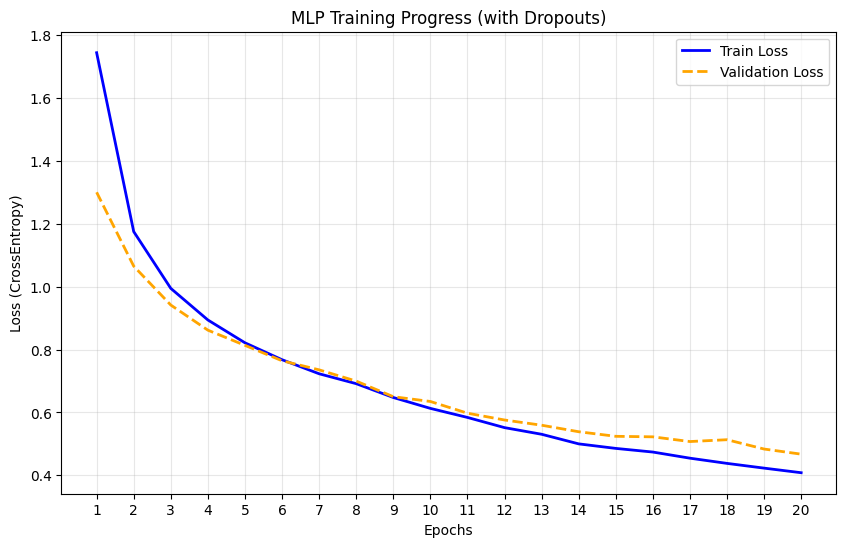

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(mlp_train_losses, label='Train Loss', color='blue', linewidth=2)
plt.plot(mlp_val_losses, label='Validation Loss', color='orange', linestyle='--', linewidth=2)

l=[i for i in range(1,21)]
m=[i for i in range(0,20)]
plt.xticks(m,l)
plt.title('MLP Training Progress (with Dropouts)')
plt.xlabel('Epochs')
plt.ylabel('Loss (CrossEntropy)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

mlp_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for X_batch, y_batch in test_loader_mlp:
        preds = mlp_model(X_batch).argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())

print(classification_report(
    all_labels,
    all_preds,
    # target_names=[le.classes_]
))

              precision    recall  f1-score   support

           0       0.90      0.96      0.93       362
           1       0.75      0.78      0.76        27
           2       0.91      0.91      0.91        82
           3       0.70      0.66      0.68        32
           4       0.98      0.96      0.97       593
           5       0.91      0.40      0.56        25
           6       1.00      0.07      0.12        15
           7       0.68      0.83      0.75        71
           8       0.39      0.31      0.35        54
           9       0.75      0.64      0.69        28
          10       0.76      0.68      0.72        28
          11       0.79      0.77      0.78        43
          12       0.92      0.79      0.85        28
          13       0.72      0.89      0.80        74
          14       0.87      0.93      0.90        29

    accuracy                           0.88      1491
   macro avg       0.80      0.71      0.72      1491
weighted avg       0.88   

2. Including Dropout + decay + momentum

In [ ]:
class MLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, num_classes)
        )
    def forward(self, x):
        return self.net(x)

mlp_model = MLP(input_dim=1500, num_classes=num_classes)
mlp_optim = torch.optim.Adam(
    mlp_model.parameters(),
    betas=(0.95, 0.99),   # ← beta1 is momentum
    weight_decay=1e-4       # ← L2 regularisation
)
criterion = nn.CrossEntropyLoss()

mlp_train_losses = []
mlp_val_losses   = []

for epoch in range(20):
    mlp_model.train()
    epoch_loss = 0
    for X_batch, y_batch in train_loader_mlp:
        mlp_optim.zero_grad()
        loss = criterion(mlp_model(X_batch), y_batch)
        loss.backward()
        mlp_optim.step()
        epoch_loss += loss.item()
    mlp_train_losses.append(epoch_loss / len(train_loader_mlp))

    mlp_model.eval()
    val_loss = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader_mlp:
            val_loss += criterion(mlp_model(X_batch), y_batch).item()
    mlp_val_losses.append(val_loss / len(val_loader_mlp))

    print(f"Epoch {epoch+1:02d} | Train Loss: {mlp_train_losses[-1]:.4f} | Val Loss: {mlp_val_losses[-1]:.4f}")

Epoch 01 | Train Loss: 1.8489 | Val Loss: 1.3640
Epoch 02 | Train Loss: 1.2603 | Val Loss: 1.1589
Epoch 03 | Train Loss: 1.0984 | Val Loss: 1.0374
Epoch 04 | Train Loss: 0.9863 | Val Loss: 0.9503
Epoch 05 | Train Loss: 0.9049 | Val Loss: 0.8913
Epoch 06 | Train Loss: 0.8450 | Val Loss: 0.8404
Epoch 07 | Train Loss: 0.8047 | Val Loss: 0.8075
Epoch 08 | Train Loss: 0.7671 | Val Loss: 0.7773
Epoch 09 | Train Loss: 0.7292 | Val Loss: 0.7385
Epoch 10 | Train Loss: 0.6909 | Val Loss: 0.6930
Epoch 11 | Train Loss: 0.6554 | Val Loss: 0.6649
Epoch 12 | Train Loss: 0.6168 | Val Loss: 0.6313
Epoch 13 | Train Loss: 0.5963 | Val Loss: 0.6283
Epoch 14 | Train Loss: 0.5689 | Val Loss: 0.6014
Epoch 15 | Train Loss: 0.5481 | Val Loss: 0.5801
Epoch 16 | Train Loss: 0.5382 | Val Loss: 0.5720
Epoch 17 | Train Loss: 0.5217 | Val Loss: 0.5759
Epoch 18 | Train Loss: 0.5076 | Val Loss: 0.5483
Epoch 19 | Train Loss: 0.4940 | Val Loss: 0.5309
Epoch 20 | Train Loss: 0.4839 | Val Loss: 0.5252


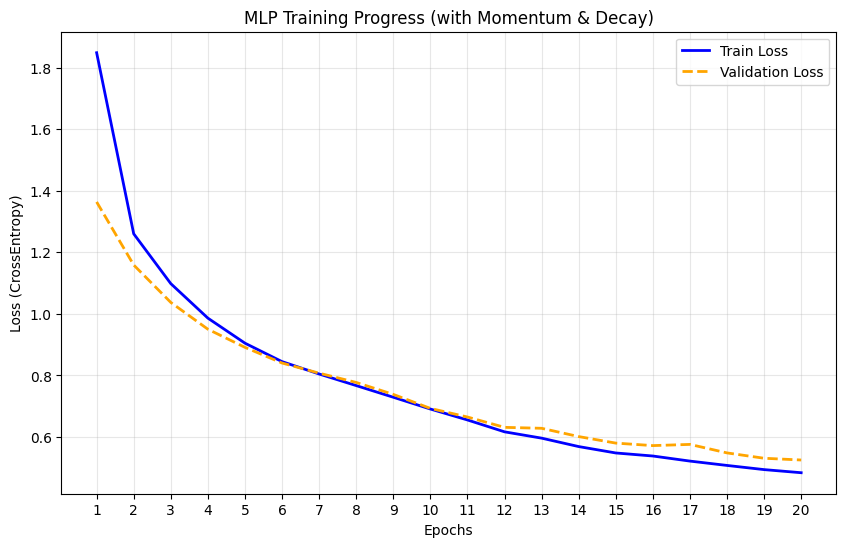

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(mlp_train_losses, label='Train Loss', color='blue', linewidth=2)
plt.plot(mlp_val_losses, label='Validation Loss', color='orange', linestyle='--', linewidth=2)

l=[i for i in range(1,21)]
m=[i for i in range(0,20)]
plt.xticks(m,l)
plt.title('MLP Training Progress (with Momentum & Decay)')
plt.xlabel('Epochs')
plt.ylabel('Loss (CrossEntropy)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

##GRID SEARCH

In [ ]:
import torch
import torch.nn as nn
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import jaccard_score
from itertools import product
from tqdm import tqdm

#gpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

param_grid = {
    'hidden_dim'  : [(128, 64), (256, 128)],
    'dropout'     : [(0.3, 0.3), (0.3, 0.2), (0.25, 0.20)],
    'lr'          : [1e-3, 5e-4],
    'beta1'       : [0.90, 0.95],
    'weight_decay': [1e-5, 1e-4]
}

# NN model
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, dropout, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim[0]),
            nn.ReLU(),
            nn.Dropout(dropout[0]),
            nn.Linear(hidden_dim[0], hidden_dim[1]),
            nn.ReLU(),
            nn.Dropout(dropout[1]),
            nn.Linear(hidden_dim[1], num_classes)
        )

    def forward(self, x):
        return self.net(x)


In [ ]:
X_tensor = torch.FloatTensor(X_train).to(device)
y_tensor = torch.LongTensor(y_train).to(device)

# CV setup
skf       = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
criterion = nn.CrossEntropyLoss()
results   = []

keys   = list(param_grid.keys())
combos = list(product(*param_grid.values()))


combo_bar = tqdm(combos, desc="Combos", unit="combo", leave=True)

for i, combo in enumerate(combo_bar):
    params = dict(zip(keys, combo))

    fold_train_jaccards = []
    fold_val_jaccards   = []

    fold_bar = tqdm(
        enumerate(skf.split(y_train, y_train)),
        total = 5,
        desc  = "  Folds",
        unit  = "fold",
        leave = False,
    )

    for fold, (train_idx, val_idx) in fold_bar:
        X_tr,  X_val = X_tensor[train_idx], X_tensor[val_idx]
        y_tr,  y_val = y_tensor[train_idx], y_tensor[val_idx]

        model = MLP(
            input_dim   = X_tensor.shape[1],
            hidden_dim  = params['hidden_dim'],
            dropout     = params['dropout'],
            num_classes = num_classes
        ).to(device)

        optimiser = torch.optim.Adam(
            model.parameters(),
            lr           = params['lr'],
            betas        = (params['beta1'], 0.999),
            weight_decay = params['weight_decay']  # ← passed in
        )

        train_ds     = torch.utils.data.TensorDataset(X_tr, y_tr)
        train_loader = torch.utils.data.DataLoader(
            train_ds, batch_size=32, shuffle=True
        )

        #Training model
        model.train()
        for epoch in range(10):
            for X_batch, y_batch in train_loader:
                optimiser.zero_grad()
                loss = criterion(model(X_batch), y_batch)
                loss.backward()
                optimiser.step()

        # Predict
        model.eval()
        with torch.no_grad():
            train_preds = model(X_tr).argmax(dim=1).cpu().numpy()
            train_jacc  = jaccard_score(y_tr.cpu().numpy(), train_preds,
                                        average='macro', zero_division=0)

            val_preds  = model(X_val).argmax(dim=1).cpu().numpy()
            val_jacc   = jaccard_score(y_val.cpu().numpy(), val_preds,
                                       average='macro', zero_division=0)

        fold_train_jaccards.append(train_jacc)
        fold_val_jaccards.append(val_jacc)

        fold_bar.set_postfix(
            tr_jacc  = f"{train_jacc:.4f}",
            val_jacc = f"{val_jacc:.4f}",
        )

In [ ]:
mean_train_jacc = np.mean(fold_train_jaccards)
    mean_val_jacc   = np.mean(fold_val_jaccards)

    results.append({
        **params,
        'mean_train_jaccard' : mean_train_jacc,
        'mean_val_jaccard'   : mean_val_jacc,
    })

    combo_bar.set_postfix(
        hidden   = str(params['hidden_dim']),
        lr       = params['lr'],
        beta1    = params['beta1'],
        wd       = params['weight_decay'],
        tr_jacc  = f"{mean_train_jacc:.4f}",
        val_jacc = f"{mean_val_jacc:.4f}",
    )

# ── 6. Best Configuration ────────────────────────────────────
best = max(results, key=lambda x: x['mean_val_jaccard'])
print(f"\nBest config: {best}")

In [ ]:
df_res=pd.DataFrame(results)
df_res['diff'] = df_res['mean_train_jaccard'] - df_res['mean_val_jaccard']
df_res.sort_values(by='diff',ascending=True)

,hidden_dim,dropout,lr,beta1,weight_decay,mean_train_jaccard,mean_val_jaccard,diff
13,"(128, 64)","(0.3, 0.2)",0.0005,0.90,0.00010,0.409277,0.408248,0.001029
5,"(128, 64)","(0.3, 0.3)",0.0005,0.90,0.00010,0.414232,0.410435,0.003797
7,"(128, 64)","(0.3, 0.3)",0.0005,0.95,0.00010,0.405723,0.401292,0.004431
4,"(128, 64)","(0.3, 0.3)",0.0005,0.90,0.00001,0.464662,0.459828,0.004834
20,"(128, 64)","(0.25, 0.2)",0.0005,0.90,0.00001,0.453551,0.447886,0.005665
47,"(256, 128)","(0.25, 0.2)",0.0005,0.95,0.00010,0.552288,0.544846,0.007441
3,"(128, 64)","(0.3, 0.3)",0.0010,0.95,0.00010,0.522021,0.514377,0.007644
28,"(256, 128)","(0.3, 0.3)",0.0005,0.90,0.00001,0.576742,0.568772,0.007969
30,"(256, 128)","(0.3, 0.3)",0.0005,0.95,0.00001,0.587504,0.578437,0.009067
21,"(128, 64)","(0.25, 0.2)",0.0005,0.90,0.00010,0.450113,0.441042,0.009071


##Final Model

In [ ]:
class MLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.25),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.net(x)

mlp_model = MLP(input_dim=X_train.shape[1], num_classes=10)
mlp_optim = torch.optim.Adam(mlp_model.parameters(), lr=0.001, weight_decay=0.0001,betas=(0.90,0.999))
criterion = nn.CrossEntropyLoss()

mlp_train_losses = []
mlp_val_losses   = []

for epoch in range(20):
    mlp_model.train()
    epoch_loss = 0
    for X_batch, y_batch in train_loader_mlp:
        mlp_optim.zero_grad()
        loss = criterion(mlp_model(X_batch), y_batch)
        loss.backward()
        mlp_optim.step()
        epoch_loss += loss.item()
    mlp_train_losses.append(epoch_loss / len(train_loader_mlp))

    mlp_model.eval()
    val_loss = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader_mlp:
            val_loss += criterion(mlp_model(X_batch), y_batch).item()
    mlp_val_losses.append(val_loss / len(val_loader_mlp))

    print(f"Epoch {epoch+1:02d} | Train Loss: {mlp_train_losses[-1]:.4f} | Val Loss: {mlp_val_losses[-1]:.4f}")

Epoch 01 | Train Loss: 1.2128 | Val Loss: 0.8769
Epoch 02 | Train Loss: 0.7260 | Val Loss: 0.6741
Epoch 03 | Train Loss: 0.5869 | Val Loss: 0.5905
Epoch 04 | Train Loss: 0.5207 | Val Loss: 0.5367
Epoch 05 | Train Loss: 0.4619 | Val Loss: 0.4947
Epoch 06 | Train Loss: 0.4264 | Val Loss: 0.4557
Epoch 07 | Train Loss: 0.3926 | Val Loss: 0.4260
Epoch 08 | Train Loss: 0.3621 | Val Loss: 0.4032
Epoch 09 | Train Loss: 0.3463 | Val Loss: 0.3970
Epoch 10 | Train Loss: 0.3278 | Val Loss: 0.3819
Epoch 11 | Train Loss: 0.3136 | Val Loss: 0.3678
Epoch 12 | Train Loss: 0.3040 | Val Loss: 0.3646
Epoch 13 | Train Loss: 0.2972 | Val Loss: 0.3534
Epoch 14 | Train Loss: 0.2818 | Val Loss: 0.3494
Epoch 15 | Train Loss: 0.2684 | Val Loss: 0.3487
Epoch 16 | Train Loss: 0.2612 | Val Loss: 0.3355
Epoch 17 | Train Loss: 0.2586 | Val Loss: 0.3431
Epoch 18 | Train Loss: 0.2489 | Val Loss: 0.3241
Epoch 19 | Train Loss: 0.2428 | Val Loss: 0.3224
Epoch 20 | Train Loss: 0.2327 | Val Loss: 0.3222


In [ ]:
torch.save(mlp_model, "mlp_model_full.pth")

In [ ]:
joblib.dump(mlp_model, "mlp_model.joblib")

['mlp_model.joblib']

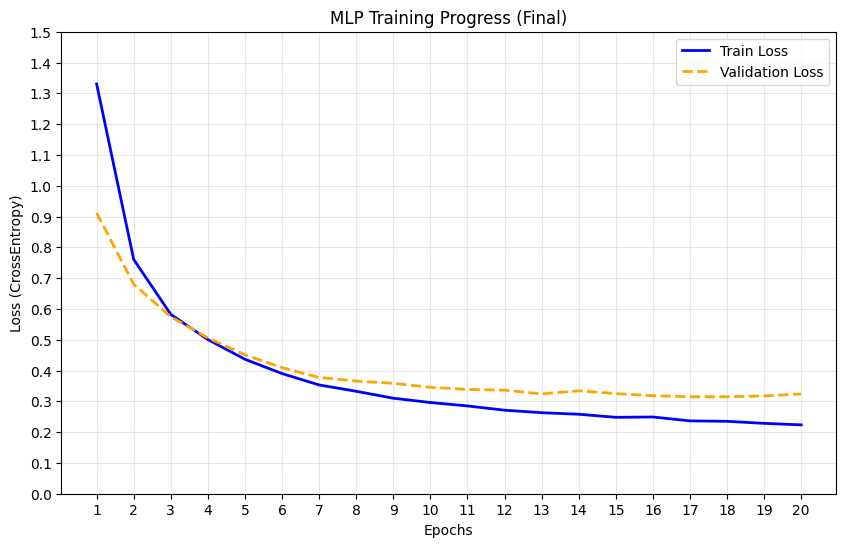

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(mlp_train_losses, label='Train Loss', color='blue', linewidth=2)
plt.plot(mlp_val_losses, label='Validation Loss', color='orange', linestyle='--', linewidth=2)

l=[i for i in range(1,21)]
m=[i for i in range(0,20)]
plt.xticks(m,l)
plt.yticks(np.arange(0, 1.6, 0.1))
plt.title('MLP Training Progress (Final)')
plt.xlabel('Epochs')
plt.ylabel('Loss (CrossEntropy)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# ── Classification report ─────────────────────────────────────
from sklearn.metrics import classification_report

mlp_model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for X_batch, y_batch in test_loader_mlp:
        all_preds.extend(mlp_model(X_batch).argmax(dim=1).cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())

print(classification_report(all_labels, all_preds))

              precision    recall  f1-score   support

           0       0.96      0.91      0.94       361
           1       0.83      0.76      0.79        38
           2       0.84      0.90      0.87        81
           3       0.93      0.99      0.96       589
           4       0.67      0.67      0.67        18
           5       0.80      0.83      0.82        77
           6       0.84      0.66      0.74        82
           7       0.88      0.64      0.74        44
           8       0.79      0.86      0.83        80
           9       0.88      0.94      0.91        32

    accuracy                           0.91      1402
   macro avg       0.84      0.82      0.83      1402
weighted avg       0.91      0.91      0.90      1402



<Figure size 1200x1000 with 0 Axes>

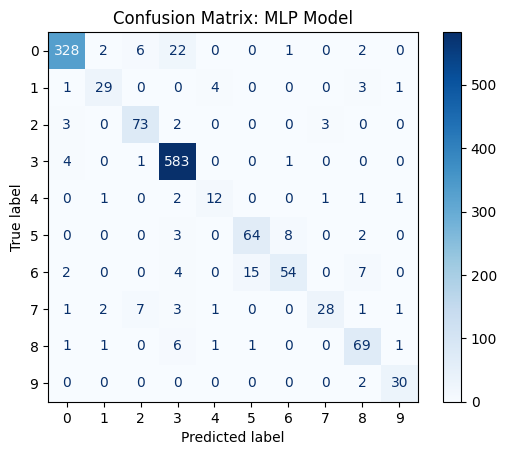

In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
plt.figure(figsize=(12, 10))
cm=confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')

plt.title('Confusion Matrix: MLP Model')
plt.show()

/tmp/ipykernel_4735/3235778646.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


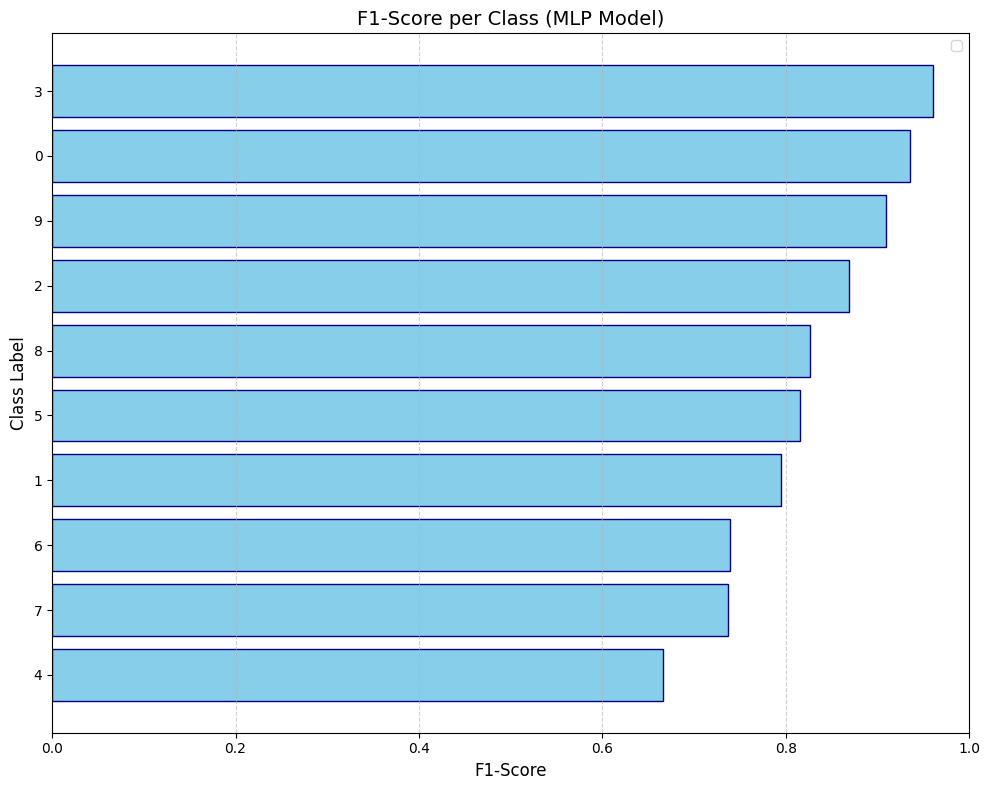

In [ ]:
#AI was used to extract f1_score from classification report plot it using barchart

report = classification_report(all_labels, all_preds, output_dict=True)

classes = [key for key in report.keys() if key not in ['accuracy', 'macro avg', 'weighted avg']]
f1_scores = [report[key]['f1-score'] for key in classes]

sorted_data = sorted(zip(classes, f1_scores), key=lambda x: x[1])
sorted_classes, sorted_f1 = zip(*sorted_data)

plt.figure(figsize=(10, 8))
bars = plt.barh(sorted_classes, sorted_f1, color='skyblue', edgecolor='navy')

plt.title('F1-Score per Class (MLP Model)', fontsize=14)
plt.xlabel('F1-Score', fontsize=12)
plt.ylabel('Class Label', fontsize=12)
plt.xlim(0, 1.0)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import f1_score,jaccard_score

score = f1_score(all_labels, all_preds, average='macro')
print(f"Macro F1 Score: {score:.4f}")

Macro F1 Score: 0.8254


In [ ]:
score=jaccard_score(all_labels, all_preds, average='macro')
print(f"Macro Jaccard Score: {score:.4f}")

Macro Jaccard Score: 0.7127


In [ ]:
mlpp